# Klasifikasi Citra Emosi Wajah Menggunakan CNN (Transfer Learning MobileNetV2) dengan Dashboard Streamlit

**Nama:** Chalista Achira
**Dataset:** [Facial Emotion Recognition Dataset (Kaggle)](https://www.kaggle.com/datasets/fahadullaha/facial-emotion-recognition-dataset/data)

## Tujuan Praktikum
1. Mengambil dan memahami dataset citra emosi wajah dari sumber terbuka (Kaggle).
2. Melakukan eksplorasi dan pra-pemrosesan data citra.
3. Membangun model klasifikasi citra menggunakan CNN.
4. Mengevaluasi performa model dengan berbagai metrik klasifikasi.
5. Menampilkan hasil analisis dan prediksi melalui dashboard interaktif Streamlit (`app.py`).

**Cara pakai:** jalankan semua cell dari atas ke bawah. Notebook ini menyimpan semua hasil ke folder `output/`,
lalu `app.py` membaca folder tersebut untuk ditampilkan di dashboard.

## Langkah 0 — Instalasi library dan import

In [1]:

# %pip install tensorflow numpy pandas matplotlib scikit-learn streamlit pillow kagglehub opencv-python-headless

In [2]:
import os
import json
import time
import random
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
from PIL import Image

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Konfigurasi
Semua parameter penting ada di sini. Kalau dataset sudah ada di komputer, isi `DATA_DIR` dengan path folder dataset.
Jika dikosongkan, notebook akan mencari folder umum (`dataset`, `data`, `archive`) lalu mencoba mengunduh dari Kaggle lewat `kagglehub`.

In [4]:

SEED = 42
DATA_DIR = os.environ.get("DATA_DIR", "")
OUT_DIR = "output"

IMG_SIZE = (96, 96)
BATCH = 32

EPOCHS = int(os.environ.get("EPOCHS", 8))
FINE_TUNE_EPOCHS = int(os.environ.get("FINE_TUNE_EPOCHS", 8))

FINE_TUNE_LAYERS = 30

LR_HEAD = 1e-3
LR_FINE = 5e-5

TEST_SIZE = 0.20
VAL_FRACTION_OF_TRAIN = 0.125

MIN_IMAGES_PER_CLASS = 50
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


## Langkah 1 — Pengambilan dan Pemahaman Dataset
Fungsi di bawah memindai folder dataset dan mengelompokkan gambar berdasarkan nama folder kelasnya.
Jika dataset punya subfolder `train/`, `test/`, atau `val/`, gambar dengan kelas yang sama otomatis digabung,
lalu dibagi ulang 80/20 sesuai instruksi praktikum. Folder "sampah" (misalnya `output`) diabaikan.

In [5]:
SPLIT_NAMES = {"train", "training", "test", "testing", "val", "valid", "validation", "images", "image", "data", "dataset"}


def scan_dataset(root):
    """Kembalikan dict {nama_kelas: [path gambar]} dari folder root."""
    found = {}
    for dirpath, _, filenames in os.walk(root):
        parts = os.path.normpath(dirpath).split(os.sep)
        if OUT_DIR in parts:
            continue
        imgs = [f for f in filenames if f.lower().endswith(IMG_EXT)]
        if not imgs:
            continue
        cname = os.path.basename(dirpath).strip().lower()
        if cname in SPLIT_NAMES:
            continue
        found.setdefault(cname, []).extend(os.path.join(dirpath, f) for f in imgs)
    return {k: v for k, v in found.items() if len(v) >= MIN_IMAGES_PER_CLASS}


def find_dataset():
    candidates = [DATA_DIR] if DATA_DIR else []
    candidates += ["dataset", "data", "archive", "facial-emotion-recognition-dataset", "FER", "emotions"]
    for c in candidates:
        if c and os.path.isdir(c) and len(scan_dataset(c)) >= 2:
            return c
    try:
        import kagglehub
        path = kagglehub.dataset_download("fahadullaha/facial-emotion-recognition-dataset")
        if len(scan_dataset(path)) >= 2:
            return path
    except Exception as e:
        print("Unduh otomatis dari Kaggle gagal:", e)
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Unduh dari Kaggle, ekstrak, lalu isi variabel DATA_DIR "
        "dengan path folder hasil ekstraksi."
    )


DATA_ROOT = find_dataset()
dataset = scan_dataset(DATA_ROOT)
class_names = sorted(dataset.keys())
NUM_CLASSES = len(class_names)
print("Folder dataset :", DATA_ROOT)
print(f"Jumlah kelas   : {NUM_CLASSES} -> {class_names}")
print("Total gambar   :", sum(len(v) for v in dataset.values()))

Folder dataset : C:\Users\Asus\.cache\kagglehub\datasets\fahadullaha\facial-emotion-recognition-dataset\versions\1
Jumlah kelas   : 7 -> ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Total gambar   : 49779


## Langkah 2 — Eksplorasi Data (EDA)
### 2.1 Distribusi jumlah gambar per kelas dan class imbalance

      kelas  jumlah_gambar  persentase
0     angry           5920       11.89
1   disgust           5920       11.89
2      fear           5920       11.89
3     happy          11398       22.90
4   neutral           8166       16.40
5       sad           6535       13.13
6  surprise           5920       11.89

Kelas terbanyak : happy (11398)
Kelas tersedikit: angry (5920)
Rasio imbalance : 1.93x -> TERDAPAT class imbalance (akan dikompensasi dengan class weight)


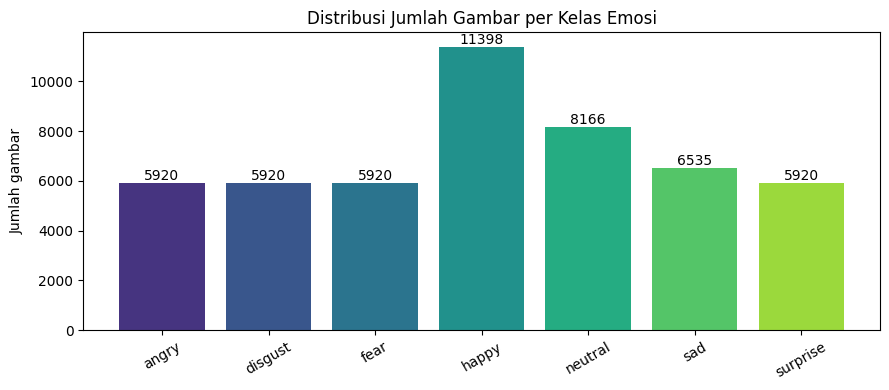

In [6]:
dist = pd.Series({c: len(dataset[c]) for c in class_names}, name="jumlah_gambar")
dist_df = dist.reset_index().rename(columns={"index": "kelas"})
dist_df["persentase"] = (dist_df["jumlah_gambar"] / dist_df["jumlah_gambar"].sum() * 100).round(2)
display(dist_df) if "display" in globals() else print(dist_df)

imbalance_ratio = dist.max() / dist.min()
print(f"\nKelas terbanyak : {dist.idxmax()} ({dist.max()})")
print(f"Kelas tersedikit: {dist.idxmin()} ({dist.min()})")
print(f"Rasio imbalance : {imbalance_ratio:.2f}x ->", "TERDAPAT class imbalance (akan dikompensasi dengan class weight)"
      if imbalance_ratio > 1.5 else "relatif seimbang")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(dist.index, dist.values, color=plt.cm.viridis(np.linspace(0.15, 0.85, NUM_CLASSES)))
ax.bar_label(bars)
ax.set_title("Distribusi Jumlah Gambar per Kelas Emosi")
ax.set_ylabel("Jumlah gambar")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "1_class_distribution.png"), dpi=120, bbox_inches="tight")
plt.show()

### 2.2 Contoh gambar tiap kelas

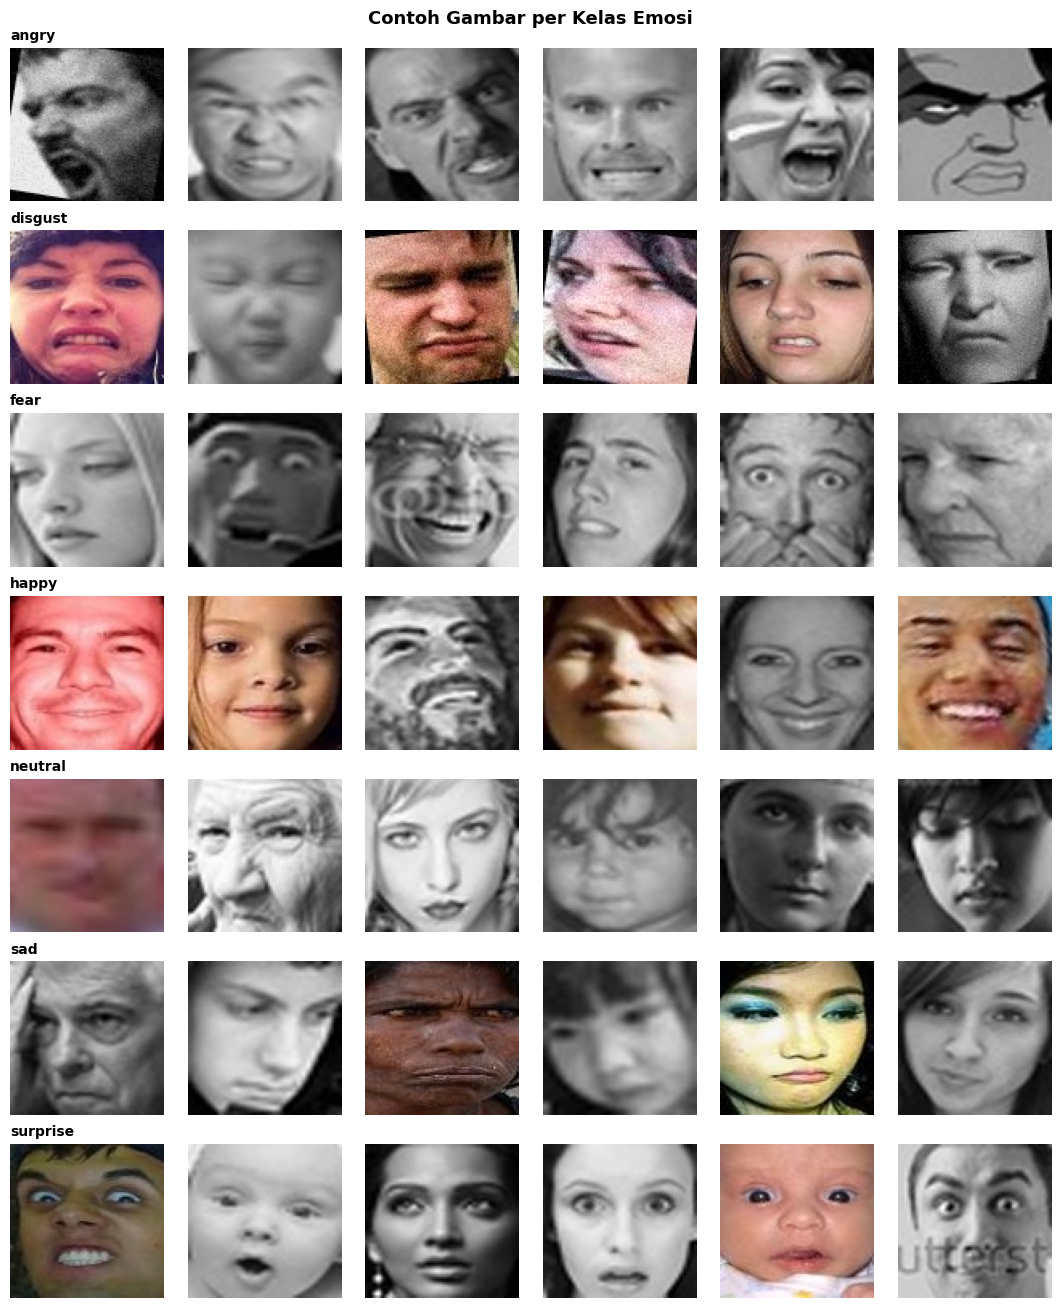

In [7]:
N_SHOW = 6
fig, axes = plt.subplots(NUM_CLASSES, N_SHOW, figsize=(N_SHOW * 1.8, NUM_CLASSES * 1.9))
axes = np.atleast_2d(axes)
for r, c in enumerate(class_names):
    picks = random.sample(dataset[c], min(N_SHOW, len(dataset[c])))
    for k in range(N_SHOW):
        ax = axes[r, k]
        ax.axis("off")
        if k < len(picks):
            ax.imshow(Image.open(picks[k]).convert("RGB"))
        if k == 0:
            ax.set_title(c, fontsize=10, loc="left", fontweight="bold")
plt.suptitle("Contoh Gambar per Kelas Emosi", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "1b_sample_per_class.png"), dpi=110, bbox_inches="tight")
plt.show()

### 2.3 Ukuran gambar, format warna, dan kualitas gambar (sampel acak)

In [8]:
all_paths = [p for c in class_names for p in dataset[c]]
sample_paths = random.sample(all_paths, min(400, len(all_paths)))

sizes, modes, brightness, contrast = [], [], [], []
for p in sample_paths:
    with Image.open(p) as im:
        sizes.append(im.size)
        modes.append(im.mode)
        g = np.asarray(im.convert("L"), dtype=np.float32)
        brightness.append(g.mean())
        contrast.append(g.std())

print("Ukuran gambar (lebar x tinggi) paling umum:", Counter(sizes).most_common(3))
print("Format warna (mode)                    :", dict(Counter(modes)))
print(f"Rata-rata kecerahan                    : {np.mean(brightness):.1f} / 255")
print(f"Rata-rata kontras (std piksel)         : {np.mean(contrast):.1f}")
print(f"Gambar kontras rendah (std < 20)       : {np.mean(np.array(contrast) < 20) * 100:.1f}%")
print(f"Gambar terlalu gelap (mean < 40)       : {np.mean(np.array(brightness) < 40) * 100:.1f}%")

Ukuran gambar (lebar x tinggi) paling umum: [((96, 96), 400)]
Format warna (mode)                    : {'RGB': 400}
Rata-rata kecerahan                    : 131.5 / 255
Rata-rata kontras (std piksel)         : 49.0
Gambar kontras rendah (std < 20)       : 0.2%
Gambar terlalu gelap (mean < 40)       : 0.5%


## Langkah 3 — Pra-Pemrosesan Data
1. Resize semua gambar ke ukuran seragam (`IMG_SIZE`). Gambar grayscale diubah ke 3 kanal agar cocok dengan MobileNetV2.
2. Normalisasi piksel ke rentang 0–1.
3. Pembagian data: **80% training** dan **20% test**. Dari bagian training, 12,5% (= 10% total) dipisah sebagai
   **validation** untuk early stopping, sehingga data test benar-benar belum pernah dilihat model.
4. Augmentasi (flip, rotasi, zoom, shift) dipasang sebagai layer di dalam model dan hanya aktif saat training.
5. Label diubah menjadi one-hot encoding.

In [9]:
paths = np.array(all_paths)
labels = np.array([class_names.index(c) for c in class_names for _ in dataset[c]])

train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths, labels, test_size=TEST_SIZE, stratify=labels, random_state=SEED)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels, test_size=VAL_FRACTION_OF_TRAIN, stratify=train_labels, random_state=SEED)

print(f"Train      : {len(train_paths)}")
print(f"Validation : {len(val_paths)}")
print(f"Test       : {len(test_paths)}")
print(f"Proporsi total -> train {len(train_paths)/len(paths)*100:.1f}% | val {len(val_paths)/len(paths)*100:.1f}% | "
      f"test {len(test_paths)/len(paths)*100:.1f}%")

AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)   # grayscale -> 3 kanal
    img = tf.image.resize(img, IMG_SIZE)                                  # resize seragam
    img = tf.cast(tf.round(img), tf.uint8)
    img.set_shape((IMG_SIZE[0], IMG_SIZE[1], 3))
    return img, label


def normalize_onehot(img, label):
    img = tf.cast(img, tf.float32) / 255.0                                # normalisasi 0-1
    return img, tf.one_hot(label, NUM_CLASSES)                            # one-hot encoding


def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).map(normalize_onehot, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


train_ds = make_ds(train_paths, train_labels, training=True)
val_ds = make_ds(val_paths, val_labels)
test_ds = make_ds(test_paths, test_labels)

# Class weight untuk mengatasi class imbalance
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_labels)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("\nClass weight:", {class_names[i]: round(w, 2) for i, w in class_weight.items()})

with open(os.path.join(OUT_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

Train      : 34845
Validation : 4978
Test       : 9956
Proporsi total -> train 70.0% | val 10.0% | test 20.0%

Class weight: {'angry': 1.2, 'disgust': 1.2, 'fear': 1.2, 'happy': 0.62, 'neutral': 0.87, 'sad': 1.09, 'surprise': 1.2}


## Langkah 4 — Pembangunan Model CNN
Arsitektur: **MobileNetV2 (pretrained ImageNet)** sebagai feature extractor, ditambah head klasifikasi:

`Input -> Augmentasi -> Rescaling [-1,1] -> MobileNetV2 -> GlobalAveragePooling -> Dense(256, ReLU) -> Dropout(0.4) -> Dense(softmax)`

- Aktivasi: **ReLU** pada hidden layer, **Softmax** pada output.
- Loss: `categorical_crossentropy`, optimizer: **Adam**.
- Training dua fase: (1) hanya head, (2) fine-tuning layer-layer terakhir MobileNetV2 dengan learning rate kecil.

In [10]:
def build_model(num_classes):
    augment = models.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.12),
        layers.RandomTranslation(0.08, 0.08),
    ], name="augmentation")

    try:
        base = tf.keras.applications.MobileNetV2(
            input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet", name="mobilenetv2")
        pretrained = True
    except Exception as e:
        print("PERINGATAN: bobot ImageNet gagal diunduh (cek koneksi internet):", e)
        print("Model dilatih dari nol -> akurasi biasanya lebih rendah. Sebaiknya jalankan ulang dengan internet aktif.")
        base = tf.keras.applications.MobileNetV2(
            input_shape=IMG_SIZE + (3,), include_top=False, weights=None, name="mobilenetv2")
        pretrained = False

    base.trainable = not pretrained

    inputs = layers.Input(shape=IMG_SIZE + (3,), name="input_image")
    x = augment(inputs)
    x = layers.Rescaling(2.0, offset=-1.0, name="to_minus1_1")(x)          # 0-1 -> [-1,1] (sesuai MobileNetV2)
    x = base(x, training=False) if pretrained else base(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(256, activation="relu", name="head_dense")(x)
    x = layers.Dropout(0.4, name="head_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="output")(x)
    return models.Model(inputs, outputs, name="emotion_mobilenetv2"), base, pretrained


model, base_model, PRETRAINED = build_model(NUM_CLASSES)
model.compile(optimizer=Adam(LR_HEAD), loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "emotion_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_minus1_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2 (Functional)        │ (None, 3, 3, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,719 (9.87 MB)

 Trainable params: 329,735 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Training fase 1 (classifier head) dan fase 2 (fine-tuning)

In [11]:
def make_callbacks():
    return [
        EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6, verbose=1),
    ]


t0 = time.time()
print("\n=== Fase 1: latih classifier head ===")
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
               class_weight=class_weight, callbacks=make_callbacks())

print("\n=== Fase 2: fine-tuning layer terakhir MobileNetV2 ===")
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:                       # BatchNorm tetap beku agar stabil
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=Adam(LR_FINE), loss="categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
               class_weight=class_weight, callbacks=make_callbacks())

train_minutes = (time.time() - t0) / 60
print(f"\nTotal waktu training: {train_minutes:.1f} menit")

history = {k: [float(v) for v in h1.history[k]] + [float(v) for v in h2.history.get(k, [])]
           for k in h1.history if k in ("accuracy", "loss", "val_accuracy", "val_loss")}
PHASE_SPLIT = len(h1.history["accuracy"])
with open(os.path.join(OUT_DIR, "history.json"), "w") as f:
    json.dump({"history": history, "phase_split": PHASE_SPLIT}, f)

model.save(os.path.join(OUT_DIR, "final_emotion_cnn_model.keras"))
print("Model disimpan ->", os.path.join(OUT_DIR, "final_emotion_cnn_model.keras"))


=== Fase 1: latih classifier head ===
Epoch 1/8
1089/1089 ━━━━━━━━━━━━━━━━━━━━ 813s 737ms/step - accuracy: 0.3910 - loss: 1.5750 - val_accuracy: 0.3915 - val_loss: 1.6096 - learning_rate: 0.0010
Epoch 2/8
1089/1089 ━━━━━━━━━━━━━━━━━━━━ 1368s 1s/step - accuracy: 0.4398 - loss: 1.4659 - val_accuracy: 0.4196 - val_loss: 1.5212 - learning_rate: 0.0010
Epoch 3/8
1089/1089 ━━━━━━━━━━━━━━━━━━━━ 1843s 2s/step - accuracy: 0.4473 - loss: 1.4387 - val_accuracy: 0.4162 - val_loss: 1.5932 - learning_rate: 0.0010
Epoch 4/8
1089/1089 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4542 - loss: 1.4238
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
1089/1089 ━━━━━━━━━━━━━━━━━━━━ 1654s 2s/step - accuracy: 0.4542 - loss: 1.4238 - val_accuracy: 0.4307 - val_loss: 1.5503 - learning_rate: 0.0010
Epoch 5/8
1089/1089 ━━━━━━━━━━━━━━━━━━━━ 1640s 2s/step - accuracy: 0.4760 - loss: 1.3686 - val_accuracy: 0.4486 - val_loss: 1.4875 - learning_rate: 3.0000e-04
Epoch 6/8
1089/1089 ━━━━━━━━

## Langkah 5 — Evaluasi Model pada Data Test
Prediksi memakai *test-time augmentation* ringan (rata-rata prediksi gambar asli dan gambar yang di-flip horizontal),
yang umumnya menaikkan akurasi sedikit tanpa training tambahan.

In [12]:
def predict_probs(ds, tta=True):
    p = model.predict(ds, verbose=0)
    if tta:
        flipped = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
        p = (p + model.predict(flipped, verbose=0)) / 2.0
    return p


probs_test = predict_probs(test_ds, tta=True)
y_true = np.asarray(test_labels, dtype=int)
y_pred = np.argmax(probs_test, axis=1)

acc = float(np.mean(y_true == y_pred))
p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
p_wt, r_wt, f_wt, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

print(f"Jumlah data test : {len(y_true)}")
print(f"Accuracy         : {acc:.4f}")
print(f"Precision (macro): {p_macro:.4f} | (weighted): {p_wt:.4f}")
print(f"Recall    (macro): {r_macro:.4f} | (weighted): {r_wt:.4f}")
print(f"F1-score  (macro): {f_macro:.4f} | (weighted): {f_wt:.4f}")

labels_idx = list(range(NUM_CLASSES))
report_txt = classification_report(y_true, y_pred, labels=labels_idx, target_names=class_names, digits=3, zero_division=0)
report_dict = classification_report(y_true, y_pred, labels=labels_idx, target_names=class_names,
                                    output_dict=True, zero_division=0)
print("\nCLASSIFICATION REPORT\n")
print(report_txt)

report_df = pd.DataFrame(report_dict).T.round(4)
report_df.to_csv(os.path.join(OUT_DIR, "classification_report.csv"))

metrics = {
    "accuracy": acc,
    "precision_macro": float(p_macro), "recall_macro": float(r_macro), "f1_macro": float(f_macro),
    "precision_weighted": float(p_wt), "recall_weighted": float(r_wt), "f1_weighted": float(f_wt),
    "per_class": {c: {k: float(report_dict[c][k]) for k in ("precision", "recall", "f1-score", "support")}
                  for c in class_names},
    "n_test": int(len(y_true)),
    "pretrained_imagenet": bool(PRETRAINED),
}
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

# Interpretasi otomatis
f1_per_class = {c: report_dict[c]["f1-score"] for c in class_names}
best_c = max(f1_per_class, key=f1_per_class.get)
worst_c = min(f1_per_class, key=f1_per_class.get)
print("INTERPRETASI")
print(f"- Akurasi {acc*100:.2f}% -> " + ("model mampu mengenali emosi dengan baik." if acc >= 0.7 else
      "akurasi masih di bawah 70%; lihat saran peningkatan di bagian bawah notebook."))
print(f"- F1-score macro {f_macro:.3f} -> " + ("keseimbangan presisi dan recall baik di semua kelas." if f_macro >= 0.7 else
      "keseimbangan presisi-recall antar kelas belum optimal."))
print(f"- Kelas paling mudah dikenali: {best_c} (F1 {f1_per_class[best_c]:.3f}); paling sulit: {worst_c} (F1 {f1_per_class[worst_c]:.3f}).")

Jumlah data test : 9956
Accuracy         : 0.5748
Precision (macro): 0.5693 | (weighted): 0.5936
Recall    (macro): 0.5598 | (weighted): 0.5748
F1-score  (macro): 0.5503 | (weighted): 0.5715

CLASSIFICATION REPORT

              precision    recall  f1-score   support

       angry      0.471     0.427     0.447      1184
     disgust      0.564     0.834     0.673      1184
        fear      0.489     0.273     0.350      1184
       happy      0.814     0.735     0.773      2280
     neutral      0.562     0.450     0.500      1633
         sad      0.377     0.614     0.467      1307
    surprise      0.708     0.587     0.642      1184

    accuracy                          0.575      9956
   macro avg      0.569     0.560     0.550      9956
weighted avg      0.594     0.575     0.572      9956

INTERPRETASI
- Akurasi 57.48% -> akurasi masih di bawah 70%; lihat saran peningkatan di bagian bawah notebook.
- F1-score macro 0.550 -> keseimbangan presisi-recall antar kelas belum optim

## Langkah 6 — Visualisasi Hasil
### 6.1 Grafik akurasi dan loss selama training

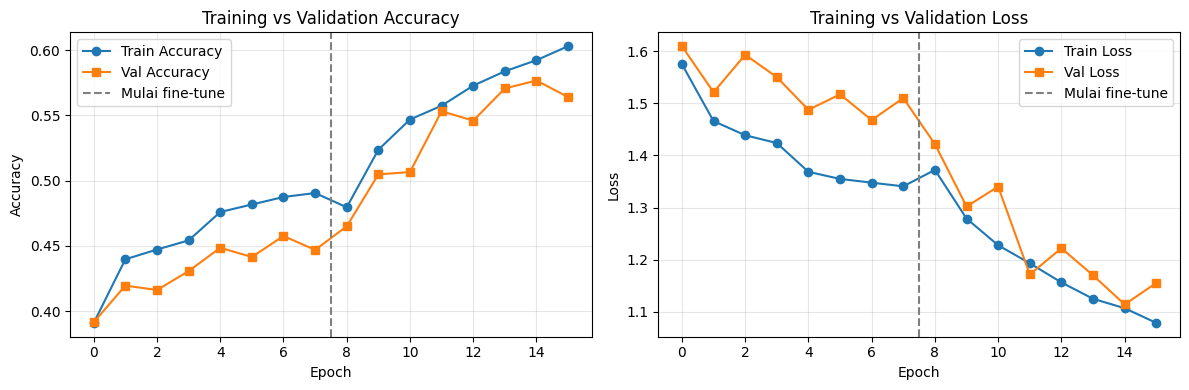

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (metric, title) in zip(ax, [("accuracy", "Accuracy"), ("loss", "Loss")]):
    a.plot(history[metric], "o-", label=f"Train {title}")
    a.plot(history[f"val_{metric}"], "s-", label=f"Val {title}")
    if 0 < PHASE_SPLIT < len(history[metric]):
        a.axvline(PHASE_SPLIT - 0.5, color="gray", linestyle="--", label="Mulai fine-tune")
    a.set_title(f"Training vs Validation {title}")
    a.set_xlabel("Epoch")
    a.set_ylabel(title)
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "2_training_curves.png"), dpi=120, bbox_inches="tight")
plt.show()

### 6.2 Confusion matrix

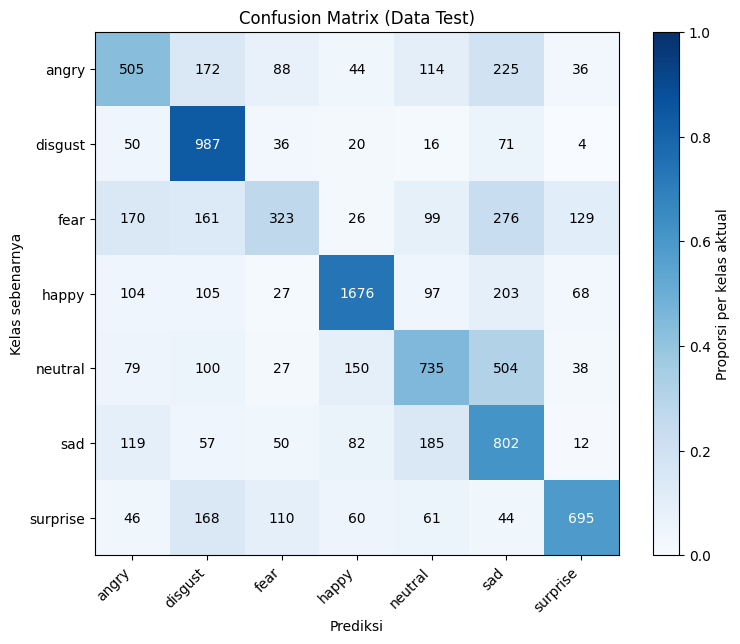

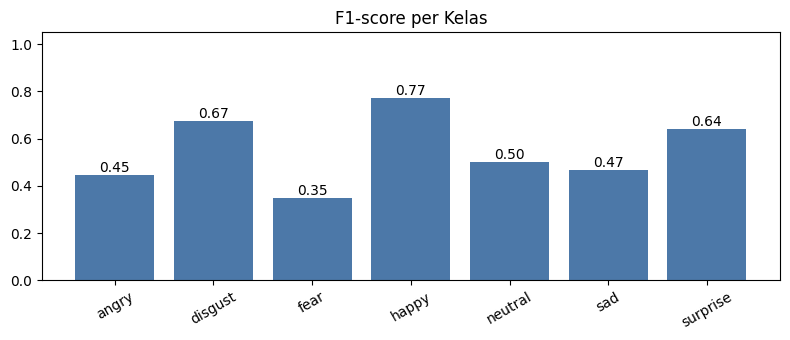

In [14]:
cm = confusion_matrix(y_true, y_pred, labels=labels_idx)
np.save(os.path.join(OUT_DIR, "confusion_matrix.npy"), cm)
cm_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proporsi per kelas aktual")
ax.set_xticks(labels_idx)
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(labels_idx)
ax.set_yticklabels(class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm_pct[i, j] > 0.5 else "black")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Kelas sebenarnya")
ax.set_title("Confusion Matrix (Data Test)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "3_confusion_matrix.png"), dpi=120, bbox_inches="tight")
plt.show()

# F1 per kelas
fig, ax = plt.subplots(figsize=(8, 3.5))
vals = [f1_per_class[c] for c in class_names]
bars = ax.bar(class_names, vals, color="#4c78a8")
ax.bar_label(bars, fmt="%.2f")
ax.set_ylim(0, 1.05)
ax.set_title("F1-score per Kelas")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "3b_f1_per_class.png"), dpi=120, bbox_inches="tight")
plt.show()

### 6.3 Feature importance (Grad-CAM)
Grad-CAM menunjukkan area gambar yang paling memengaruhi keputusan model (merah/kuning = pengaruh tinggi).

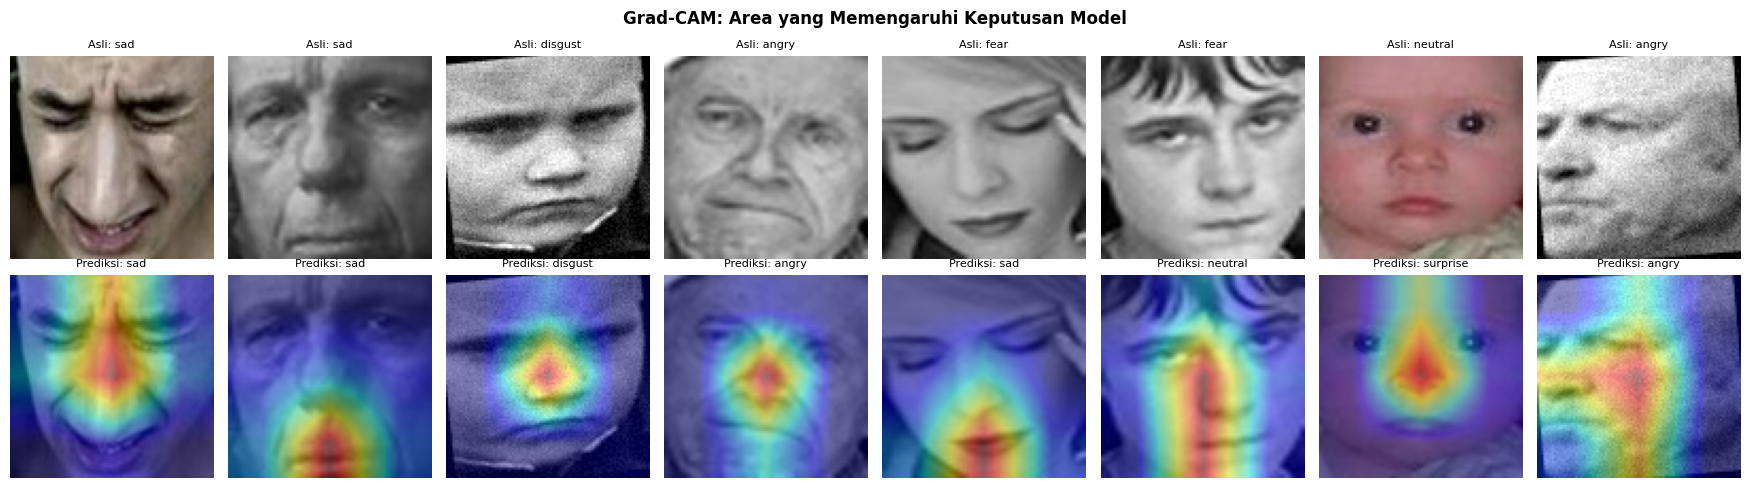

In [15]:
def grad_cam(img01, class_idx=None):
    """img01: array (H, W, 3) berskala 0-1. Kembalikan (heatmap 0-1, kelas, probabilitas)."""
    x = tf.convert_to_tensor(img01[None], tf.float32) * 2.0 - 1.0
    with tf.GradientTape() as tape:
        conv = base_model(x, training=False)
        h = model.get_layer("gap")(conv)
        h = model.get_layer("head_dense")(h)
        h = model.get_layer("head_dropout")(h, training=False)
        preds = model.get_layer("output")(h)
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]
    return cam, class_idx, preds[0].numpy()


# Ambil 8 gambar test pertama
x_batch, _ = next(iter(test_ds.take(1)))
x_batch = x_batch.numpy()
n_cam = min(8, len(x_batch))
fig, axes = plt.subplots(2, n_cam, figsize=(n_cam * 2.2, 5))
axes = np.atleast_2d(axes)
for i in range(n_cam):
    cam, cidx, _ = grad_cam(x_batch[i])
    axes[0, i].imshow(x_batch[i])
    axes[0, i].set_title(f"Asli: {class_names[y_true[i]]}", fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].imshow(x_batch[i])
    axes[1, i].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, i].set_title(f"Prediksi: {class_names[cidx]}", fontsize=8)
    axes[1, i].axis("off")
plt.suptitle("Grad-CAM: Area yang Memengaruhi Keputusan Model", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "5_gradcam.png"), dpi=120, bbox_inches="tight")
plt.show()

### 6.4 Contoh prediksi pada data test beserta label aslinya

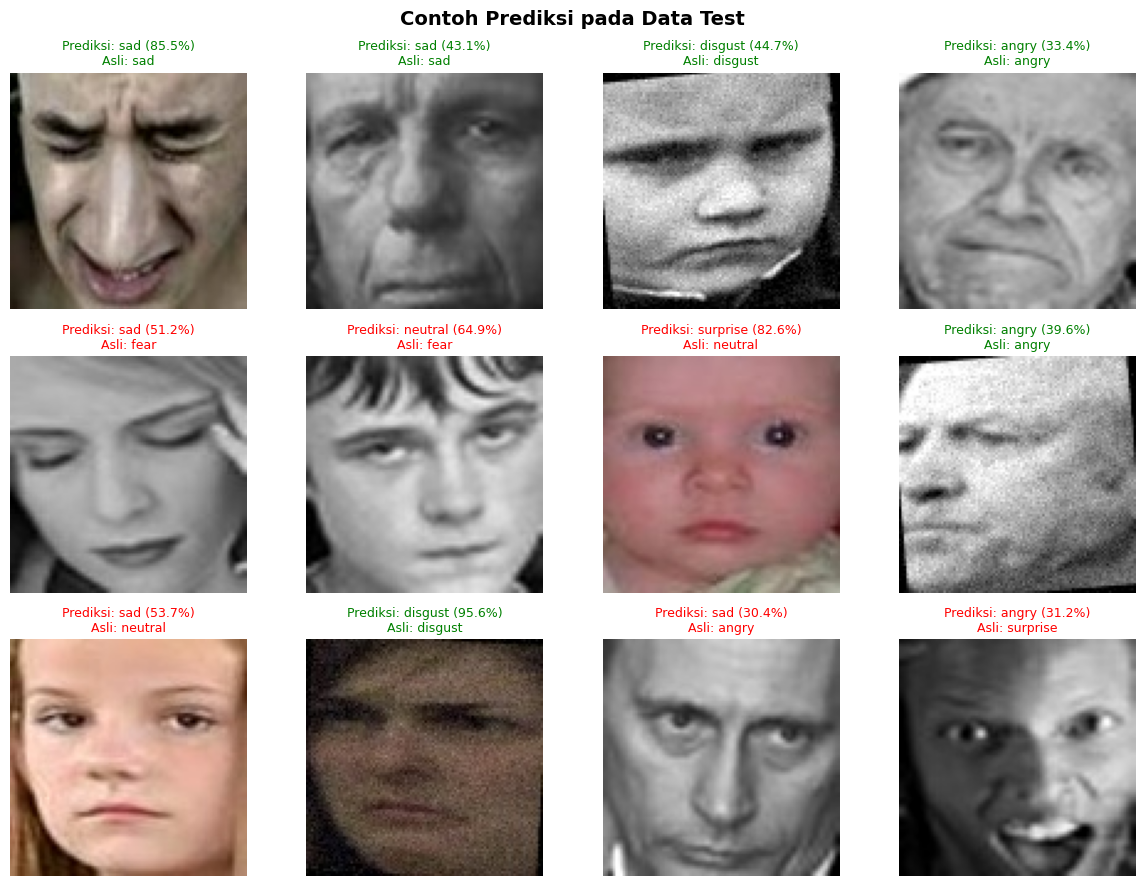

In [16]:
n_show = min(12, len(x_batch))
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()
for i, a in enumerate(axes):
    if i >= n_show:
        a.axis("off")
        continue
    pred = int(y_pred[i])
    true = int(y_true[i])
    conf = probs_test[i][pred] * 100
    a.imshow(x_batch[i])
    a.set_title(f"Prediksi: {class_names[pred]} ({conf:.1f}%)\nAsli: {class_names[true]}",
                color="green" if pred == true else "red", fontsize=9)
    a.axis("off")
plt.suptitle("Contoh Prediksi pada Data Test", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "4_sample_predictions.png"), dpi=120, bbox_inches="tight")
plt.show()

## Ringkasan dataset untuk dashboard dan laporan

In [18]:
summary = {
    "dataset_name": "Facial Emotion Recognition Dataset (Kaggle: fahadullaha)",
    "num_classes": NUM_CLASSES,
    "class_names": class_names,
    "class_counts": {c: int(len(dataset[c])) for c in class_names},
    "total_images": int(len(paths)),
    "n_train": int(len(train_paths)),
    "n_val": int(len(val_paths)),
    "n_test": int(len(test_paths)),
    "img_size": list(IMG_SIZE),
    "batch_size": BATCH,
    "epochs_phase1_max": EPOCHS,
    "epochs_phase2_max": FINE_TUNE_EPOCHS,
    "epochs_phase1_run": int(PHASE_SPLIT),
    "epochs_phase2_run": int(len(history["accuracy"]) - PHASE_SPLIT),
    "fine_tune_layers": FINE_TUNE_LAYERS,
    "lr_head": LR_HEAD,
    "lr_fine": LR_FINE,
    "optimizer": "Adam",
    "train_minutes": round(train_minutes, 2),
    "total_params": int(model.count_params()),
    "imbalance_ratio": float(imbalance_ratio),
    "pretrained_imagenet": bool(PRETRAINED),
}
with open(os.path.join(OUT_DIR, "dataset_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "dataset_name": "Facial Emotion Recognition Dataset (Kaggle: fahadullaha)",
  "num_classes": 7,
  "class_names": [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "sad",
    "surprise"
  ],
  "class_counts": {
    "angry": 5920,
    "disgust": 5920,
    "fear": 5920,
    "happy": 11398,
    "neutral": 8166,
    "sad": 6535,
    "surprise": 5920
  },
  "total_images": 49779,
  "n_train": 34845,
  "n_val": 4978,
  "n_test": 9956,
  "img_size": [
    96,
    96
  ],
  "batch_size": 32,
  "epochs_phase1_max": 8,
  "epochs_phase2_max": 8,
  "epochs_phase1_run": 8,
  "epochs_phase2_run": 8,
  "fine_tune_layers": 30,
  "lr_head": 0.001,
  "lr_fine": 5e-05,
  "optimizer": "Adam",
  "train_minutes": 344.42,
  "total_params": 2587719,
  "imbalance_ratio": 1.9253378378378379,
  "pretrained_imagenet": true
}


## Memuat ulang model (verifikasi) dan lokasi hasil

In [19]:
loaded = tf.keras.models.load_model(os.path.join(OUT_DIR, "final_emotion_cnn_model.keras"))
chk = np.argmax(loaded.predict(x_batch[:8], verbose=0), axis=1)
print("Model berhasil di-load ulang. Contoh prediksi:", [class_names[i] for i in chk])
print("\nHasil disimpan di:", os.path.abspath(OUT_DIR))
for fn in sorted(os.listdir(OUT_DIR)):
    print(" -", fn)
print("\nLanjut: jalankan dashboard dengan  ->  streamlit run app.py")

Model berhasil di-load ulang. Contoh prediksi: ['sad', 'sad', 'disgust', 'angry', 'sad', 'neutral', 'surprise', 'angry']

Hasil disimpan di: c:\Users\Asus\Desktop\KULIAH CHALISTA ACHIRA\SEMESTER 7\ANALISIS BIG DATA\Chalista Achira_KlasifikasiEmosiWajah\output
 - 1_class_distribution.png
 - 1b_sample_per_class.png
 - 2_training_curves.png
 - 3_confusion_matrix.png
 - 3b_f1_per_class.png
 - 4_sample_predictions.png
 - 5_gradcam.png
 - class_names.json
 - classification_report.csv
 - confusion_matrix.npy
 - dataset_summary.json
 - final_emotion_cnn_model.keras
 - history.json
 - metrics.json

Lanjut: jalankan dashboard dengan  ->  streamlit run app.py


## Kesimpulan dan Analisis Hasil